In [3]:
%run sokoradar_pipeline.py

SokoRadar pipeline | Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | matplotlib 3.10.0 | openpyxl 3.1.5
No raw/ folder found - unpacking the raw data embedded in this script to /content/sokoradar_raw_data
Raw data: /content/sokoradar_raw_data
Output:   /content/output
[14:41:06] 1/8 Loading counties, national drivers and MoA daily prices
[14:41:06] 2/8 Cleaning outliers in MoA daily prices; reading the MoA bulletin
[14:41:07] 3/8 Monthly MoA prices and filling missing months
MoA: 692 days x 42 commodities; removed 93 values
[14:41:08] 4/8 Loading and cleaning WFP market prices
WFP: 24,944 prices after cleaning; removed 17
[14:41:10] 5/8 Building national price series 2006-2024
[14:41:11] 6/8 County prices (observed + estimated), wholesale and retail
markups {'maize': 1.39, 'sorghum': 1.01, 'beans': 1.18, 'potatoes': 1.65}
accuracy (median abs % error, neighbours vs own data): {('beans', 'Wholesale'): 8.7, ('beef', 'Retail'): 3.7, ('goat meat', 'Retail'): 7.4, ('maize', 'Wholesale'): 13.3

In [5]:
from google.colab import files
files.download("output.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [7]:
import pandas as pd

long_df = pd.read_csv("output/SokoRadar_County_2006_2024_long.csv")
print(long_df.shape)
long_df.head(10)

(278616, 9)


,month,county_code,county,commodity,price_type,unit,price_kes,flag,n_markets
0,2006-01,1,Mombasa,Beans Canadian,Retail,KES/kg,43.48,Estimated: own county trend,NaN
1,2006-02,1,Mombasa,Beans Canadian,Retail,KES/kg,46.38,Estimated: own county trend,NaN
2,2006-03,1,Mombasa,Beans Canadian,Retail,KES/kg,49.50,Estimated: own county trend,NaN
3,2006-04,1,Mombasa,Beans Canadian,Retail,KES/kg,51.55,Estimated: own county trend,NaN
4,2006-05,1,Mombasa,Beans Canadian,Retail,KES/kg,53.16,Estimated: own county trend,NaN
5,2006-06,1,Mombasa,Beans Canadian,Retail,KES/kg,40.01,Estimated: own county trend,NaN
6,2006-07,1,Mombasa,Beans Canadian,Retail,KES/kg,35.87,Estimated: own county trend,NaN
7,2006-08,1,Mombasa,Beans Canadian,Retail,KES/kg,34.51,Estimated: own county trend,NaN
8,2006-09,1,Mombasa,Beans Canadian,Retail,KES/kg,37.39,Estimated: own county trend,NaN
9,2006-10,1,Mombasa,Beans Canadian,Retail,KES/kg,36.88,Estimated: own county trend,NaN


In [8]:
xl = pd.ExcelFile("output/SokoRadar_County_2006_2024.xlsx")
print(xl.sheet_names)

['README', 'County_Panel', 'Price_Flags', 'National_Prices', 'MoA_Monthly_Raw', 'Cleaning_Log', 'Missing_Report', 'Observed_WFP', 'County_Ratios', 'Counties', 'Events_County', 'Charts']


1_national_price_index.png


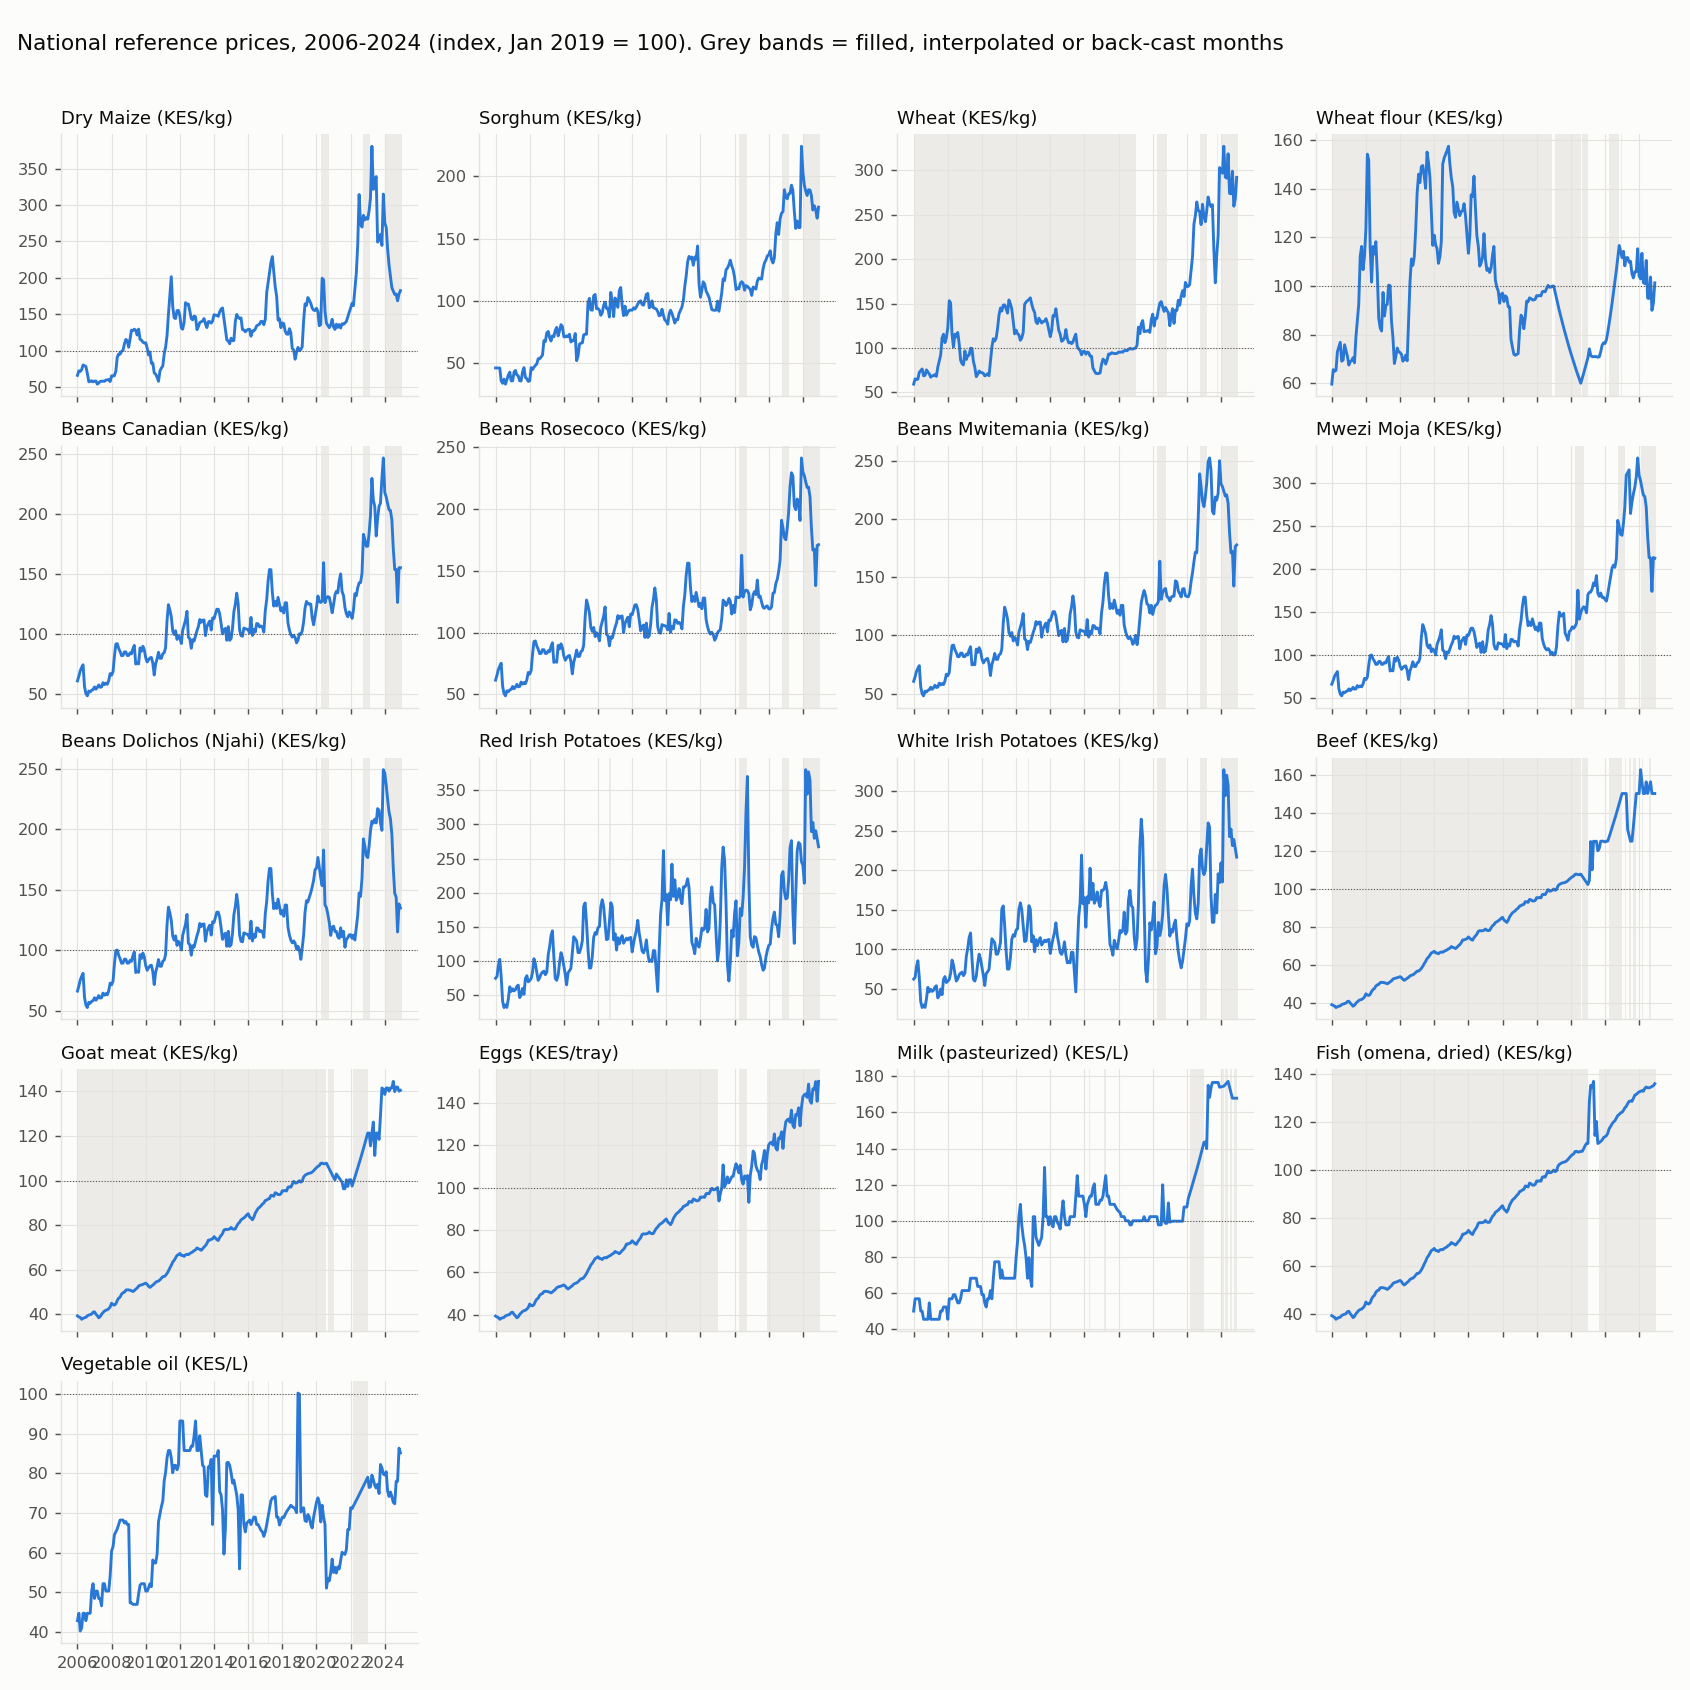

2_national_data_coverage.png


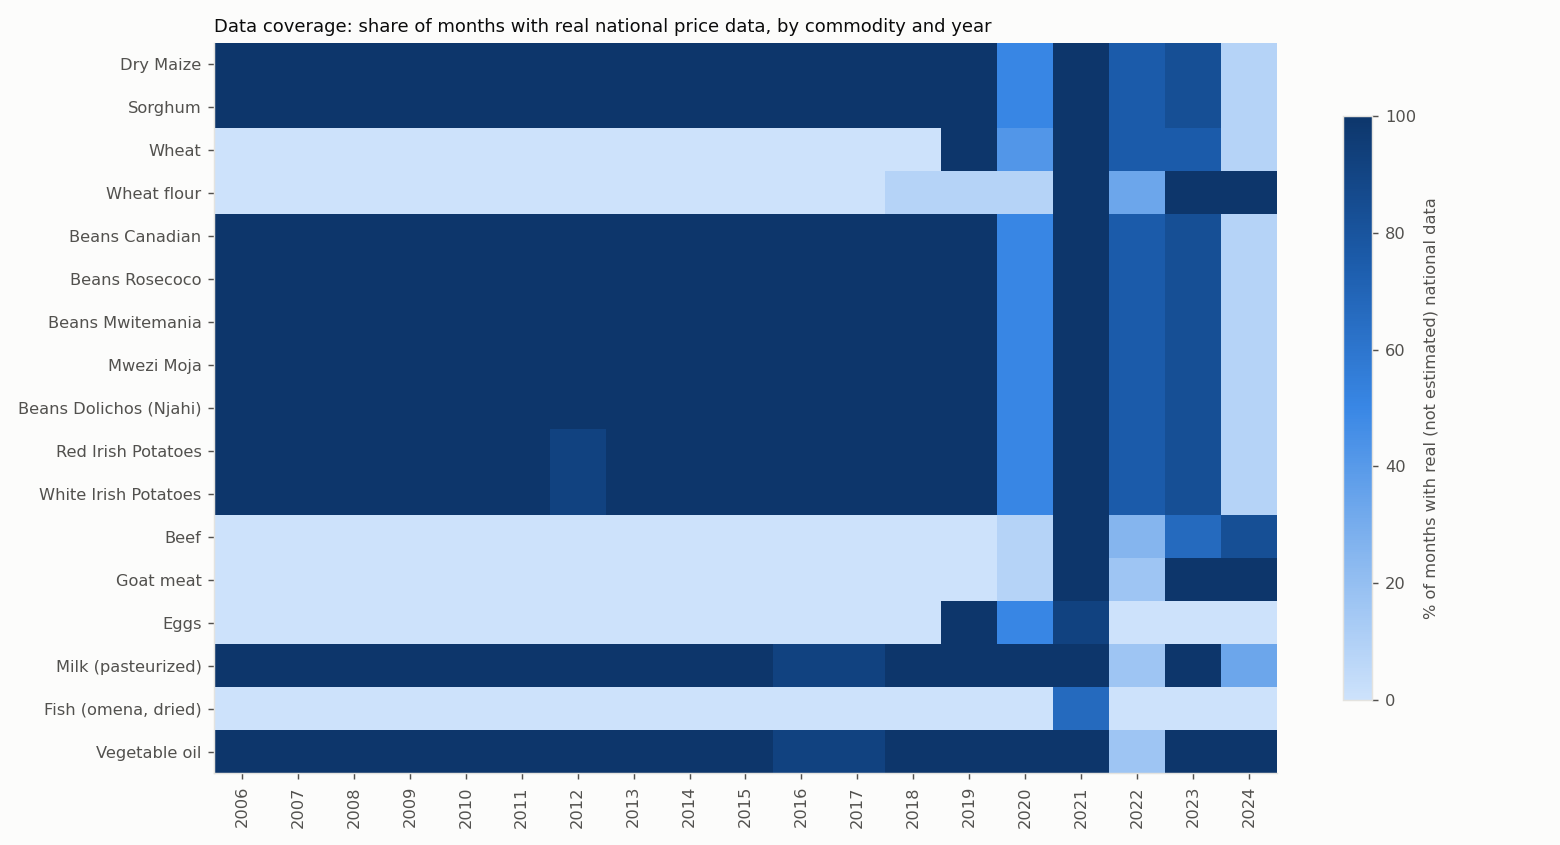

3_county_coverage.png


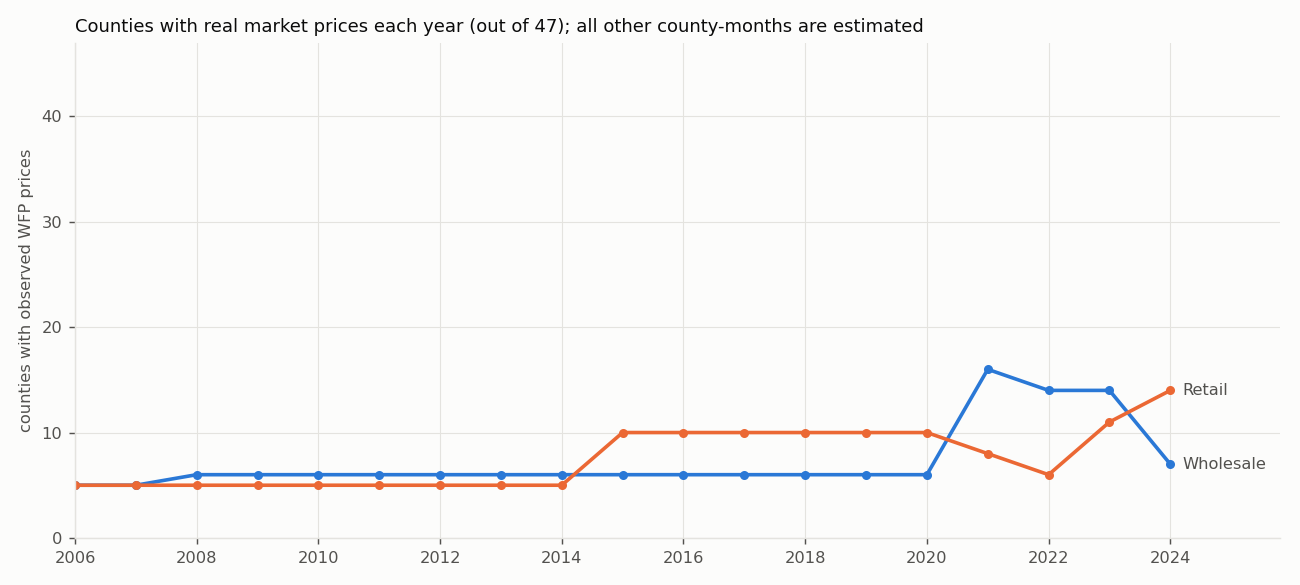

4_outliers.png


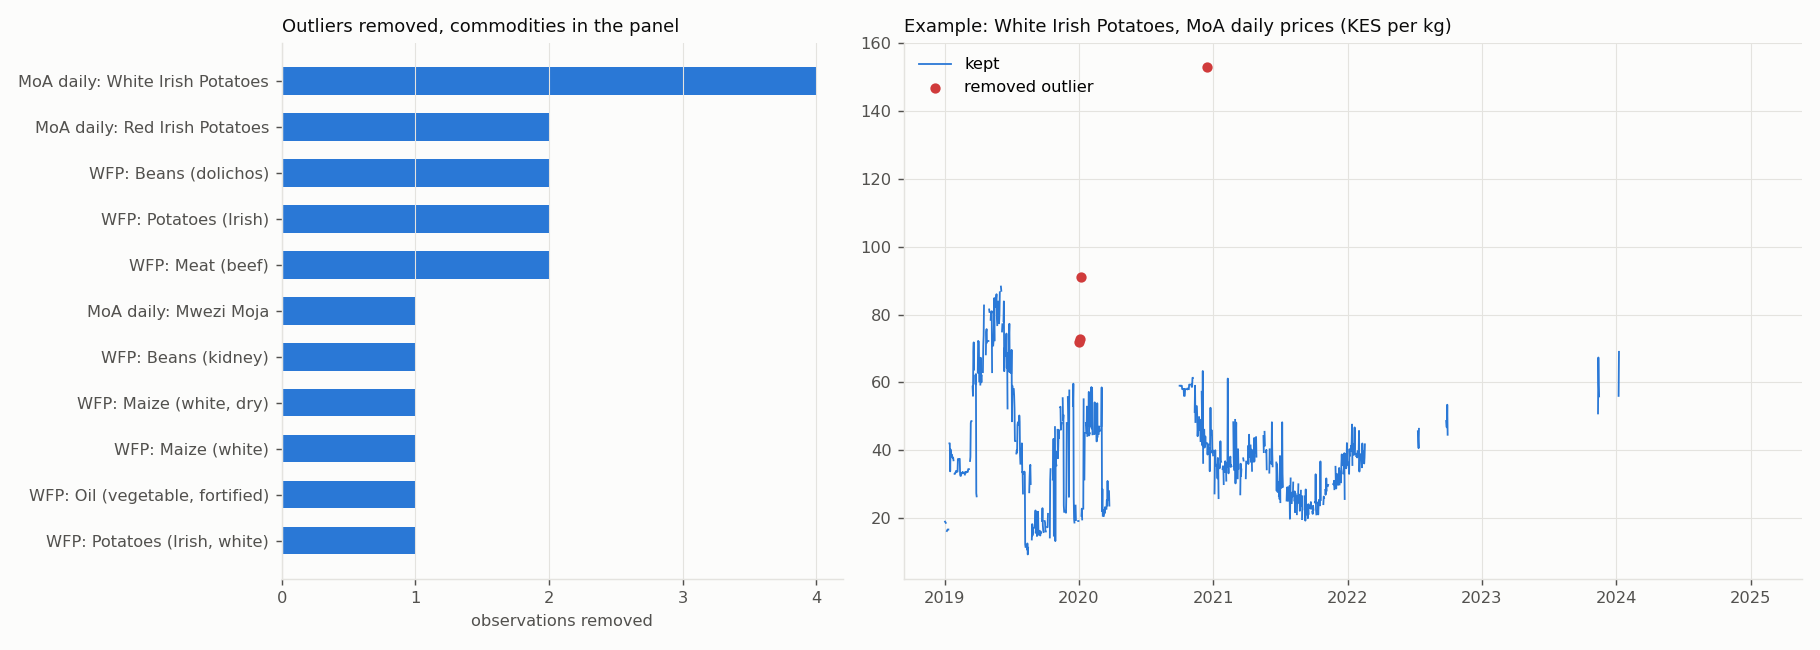

5_retail_markup.png


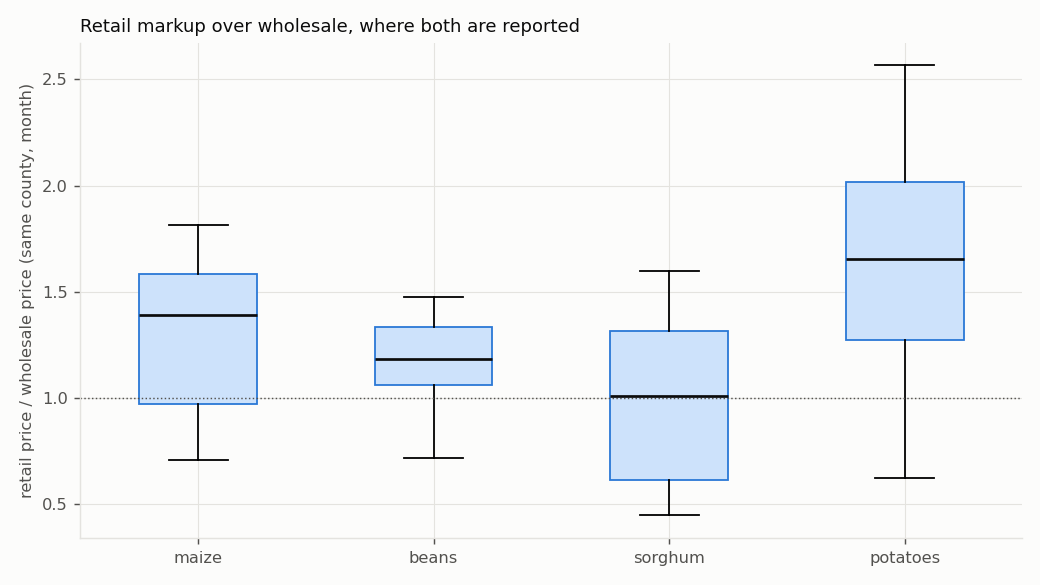

6_county_maize_price_map.png


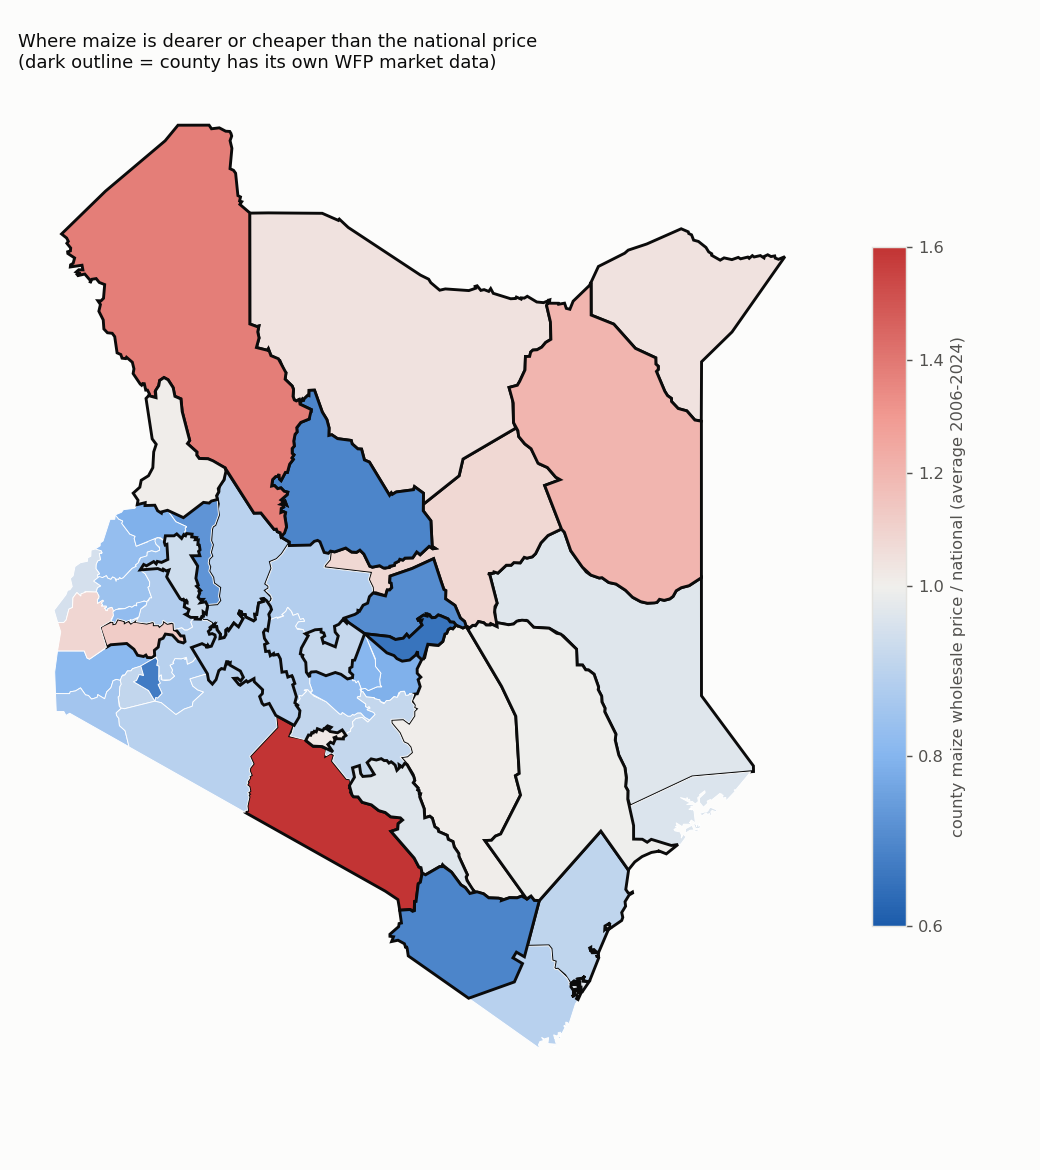

7_price_change_correlation.png


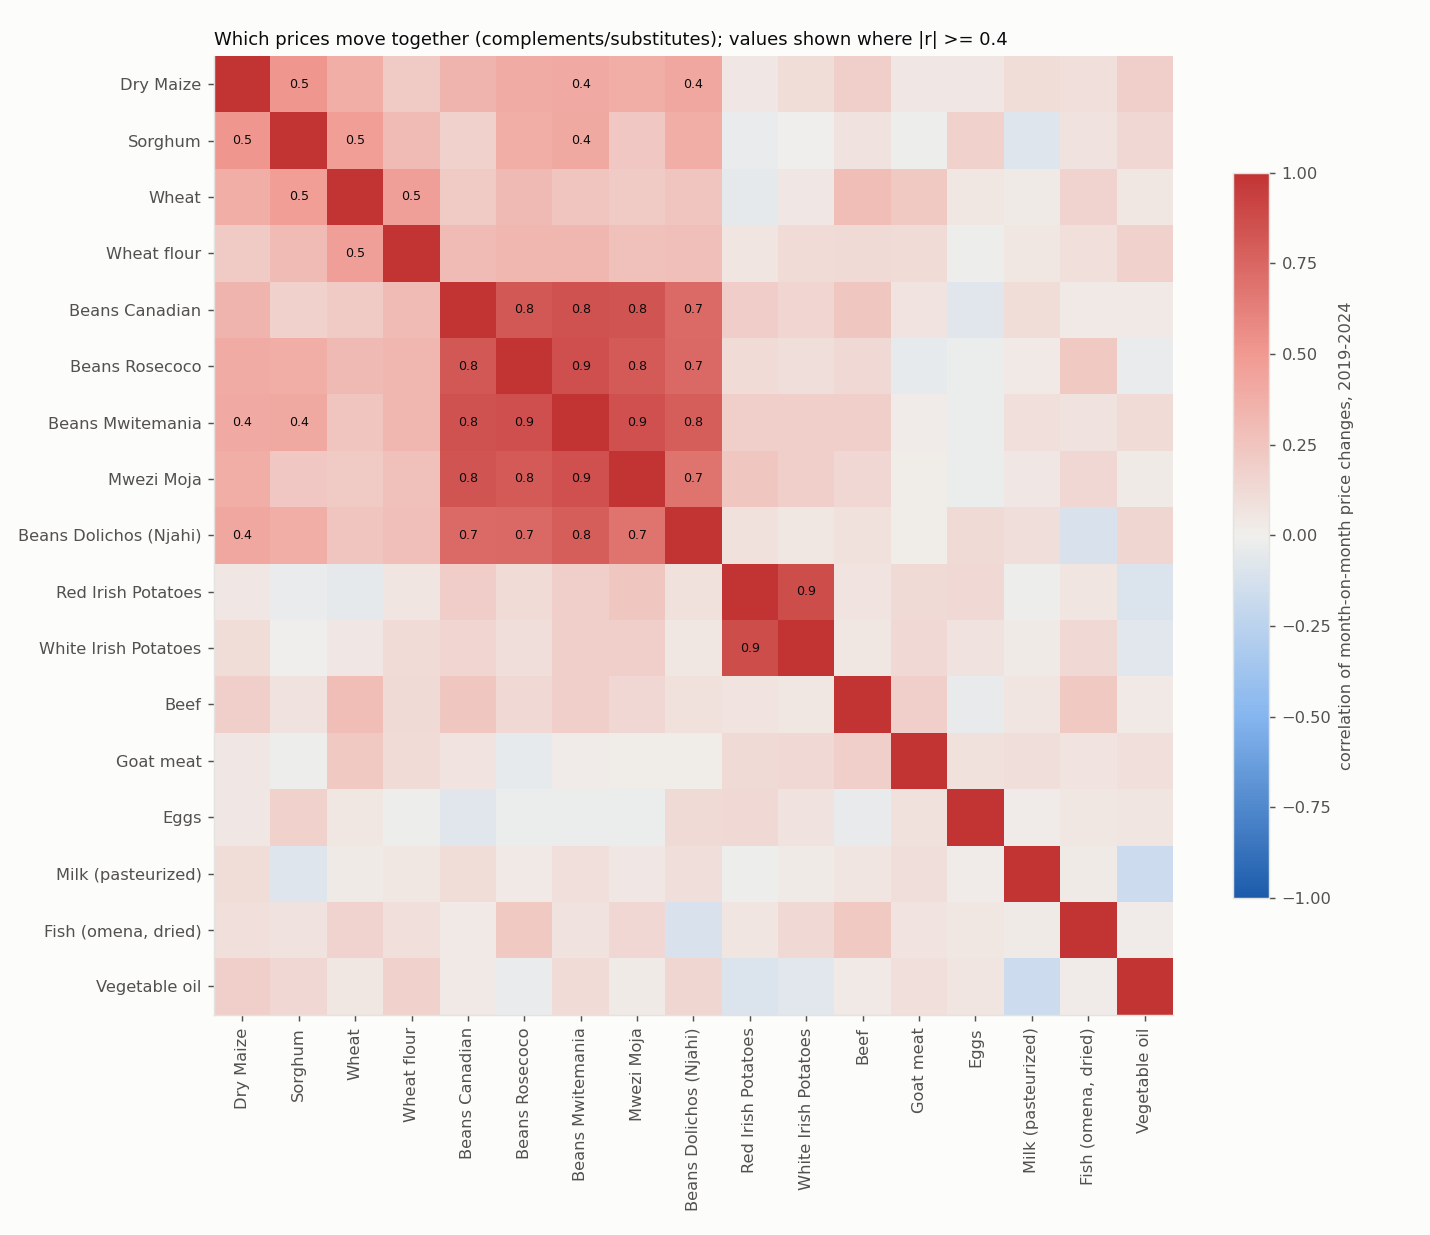

8_maize_price_and_drought.png


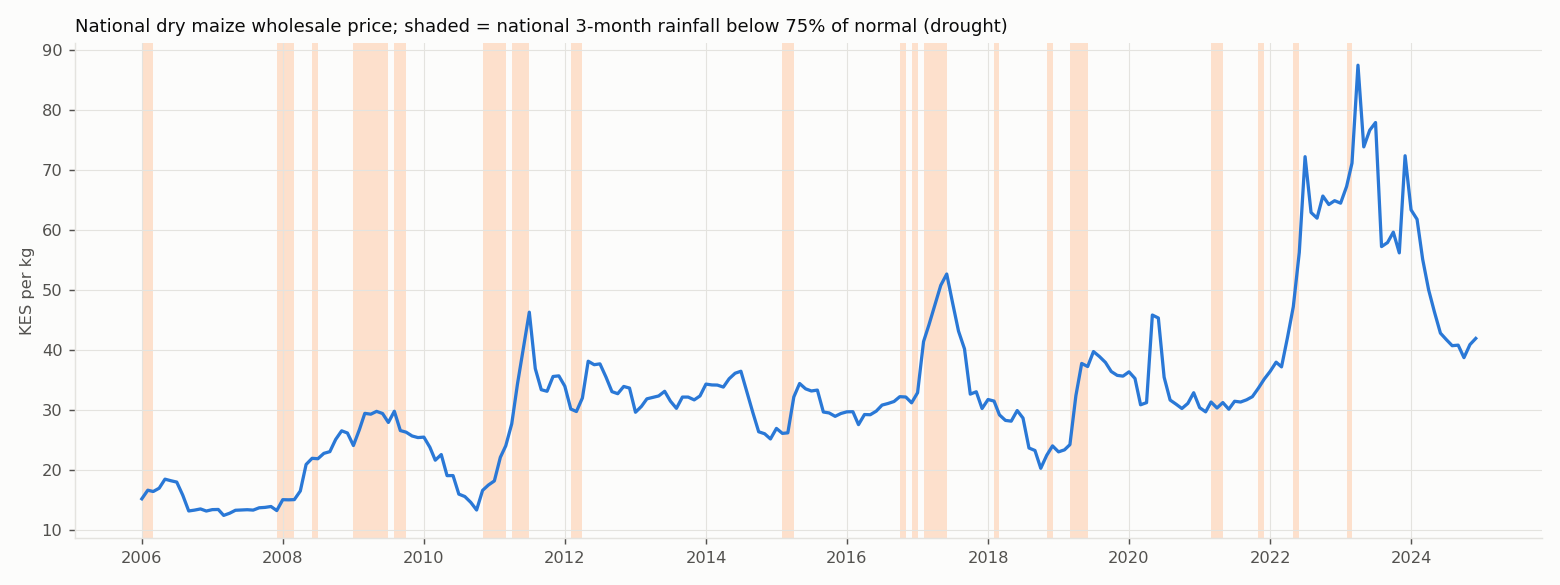

In [6]:
from IPython.display import Image, display
from pathlib import Path

for p in sorted(Path("output/figures").glob("*.png")):
    print(p.name)
    display(Image(filename=str(p)))